<a href="https://colab.research.google.com/github/pedrosampaiom2007-gif/Analise-de-dados-Airbnb-Rio/blob/main/notebooks/analise_precos_airbnb_rio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/pedrosampaiom2007-gif/Analise-de-dados-Airbnb-Rio/blob/main/notebooks/analise_precos_airbnb_rio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quanto custa uma noite no Rio? Análise de preços do Airbnb

Análise dos anúncios do Airbnb no Rio de Janeiro com Python e pandas: limpeza dos dados, tratamento de outliers e respostas para 6 perguntas.

**Fonte:** [Inside Airbnb](https://insideairbnb.com/get-the-data/), Rio de Janeiro (CC BY 4.0). Data da extração: `AAAA-MM-DD`.

## Perguntas
1. Quais são os bairros mais caros e os mais baratos?
2. Quanto custa cada tipo de acomodação nos bairros mais procurados?
3. Superhosts cobram mais e são mais bem avaliados?
4. Quais são as comodidades mais comuns? Ter piscina deixa a diária mais cara?
5. Quantos anfitriões entraram no Airbnb a cada ano?
6. Quanto custa a diária média em dólar?

## Sumário
0. Configuração
1. Coleta dos dados
2. Entendimento inicial
3. Tratamento
4. Outliers
5. Transformações
6. Análises
7. Exportação
8. Conclusões

## 0. Configuração

In [406]:
# Importa as bibliotecas usadas no projeto.
# Por quê: pandas/numpy para tratar os dados, matplotlib/seaborn para os gráficos, requests para a API do Banco Central.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

# Mostra todas as colunas ao exibir um DataFrame (a base tem mais de 70 colunas).
pd.set_option('display.max_columns', None)

## 1. Coleta dos dados

Arquivo `listings.csv.gz` (anúncios) do Rio de Janeiro, lido direto da URL.

In [407]:
# Link do listings.csv.gz do Rio (copiado de insideairbnb.com/get-the-data)
URL_LISTINGS = '/content/listings.csv'

In [408]:
# Colunas usadas na análise (as outras 60+ não são necessárias).
COLUNAS = [
    'id', 'name', 'host_id', 'host_since', 'host_response_rate', 'host_acceptance_rate',
    'host_is_superhost', 'host_identity_verified', 'host_listings_count',
    'neighbourhood_cleansed', 'latitude', 'longitude', 'property_type', 'room_type',
    'accommodates', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price',
    'minimum_nights', 'availability_365', 'number_of_reviews', 'first_review', 'last_review',
    'review_scores_rating', 'review_scores_location', 'review_scores_value', 'instant_bookable',
]

## 2. Entendimento inicial

Antes de mexer nos dados: quantas linhas, quais tipos, onde estão os nulos.

In [409]:
df=pd.read_csv(URL_LISTINGS,usecols=COLUNAS,sep=',')# lendo o arquivo

In [410]:
df.head() # Conhecendo a base de dados

,id,name,host_id,host_since,host_response_rate,host_acceptance_rate,host_is_superhost,host_listings_count,host_identity_verified,neighbourhood_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,availability_365,number_of_reviews,first_review,last_review,review_scores_rating,review_scores_location,review_scores_value,instant_bookable
0,2992450,Luxury 2 bedroom apartment,4621559,NaN,NaN,NaN,f,1,t,THIRD WARD,42.65789,-73.75370,Entire rental unit,Entire home/apt,4,1 bath,2,2.0,"[""Essentials"", ""Smoke alarm"", ""Carbon monoxide...",$65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
1,3820211,Restored Precinct in Center Sq. w/Parking,19648678,NaN,NaN,NaN,t,7,t,SIXTH WARD,42.65222,-73.76724,Entire rental unit,Entire home/apt,3,1 bath,1,1.0,"[""Smart lock"", ""Microwave"", ""Conditioner"", ""Ki...",$171.00,1.0,342,320,2014-08-15,2026-09-07,4.75,4.81,4.78,NaN
2,6623339,Center Sq. Loft in Converted Precinct w/ Parking,19648678,NaN,NaN,NaN,t,7,t,SIXTH WARD,42.65222,-73.76724,Entire rental unit,Entire home/apt,2,1 bath,1,1.0,"[""Smart lock"", ""Microwave"", ""Conditioner"", ""Ki...",$242.00,1.0,337,344,2015-06-07,2026-09-07,4.74,4.79,4.73,NaN
3,9501054,Spacious suite with full bath by Capital Center,29288920,NaN,NaN,NaN,f,2,t,SECOND WARD,42.64734,-73.75851,Private room in rental unit,Private room,2,1 private bath,1,2.0,"[""Smart lock"", ""Microwave"", ""Window AC unit"", ...",$79.00,1.0,250,479,2016-02-02,2026-09-04,4.59,4.77,4.68,NaN
4,10768745,Alb hospital area studio bath wifi. (Red),5691268,NaN,NaN,NaN,t,2,t,FOURTEENTH WARD,42.66078,-73.80553,Private room in guest suite,Private room,1,1 private bath,1,1.0,"[""Microwave"", ""Window AC unit"", ""Hangers"", ""Ca...",$50.00,1.0,142,941,2016-02-05,2026-08-30,4.84,4.93,4.91,NaN


In [411]:
df.shape # Linhas x colunas

(500, 29)

In [412]:
# Renomeando as colunas para o português

colunas_traduzidas = {
    'id': 'id',
    'name': 'nome',
    'host_id': 'anfitriao_id',
    'host_since': 'anfitriao_desde',
    'host_response_rate': 'taxa_resposta_anfitriao',
    'host_acceptance_rate': 'taxa_aceitacao_anfitriao',
    'host_is_superhost': 'anfitriao_superhost',
    'host_identity_verified': 'anfitriao_identidade_verificada',
    'host_listings_count': 'total_anuncios_anfitriao',
    'neighbourhood_cleansed': 'bairro',
    'latitude': 'latitude',
    'longitude': 'longitude',
    'property_type': 'tipo_propriedade',
    'room_type': 'tipo_quarto',
    'accommodates': 'acomoda',
    'bathrooms_text': 'banheiros_texto',
    'bedrooms': 'quartos',
    'beds': 'camas',
    'amenities': 'comodidades',
    'price': 'preco',
    'minimum_nights': 'minimo_noites',
    'availability_365': 'disponibilidade_365',
    'number_of_reviews': 'numero_avaliacoes',
    'first_review': 'primeira_avaliacao',
    'last_review': 'ultima_avaliacao',
    'review_scores_rating': 'nota_geral',
    'review_scores_location': 'nota_localizacao',
    'review_scores_value': 'nota_custo_beneficio',
    'instant_bookable': 'reserva_instantanea'
}

df.rename(columns=colunas_traduzidas, inplace=True)
display(df.head())

,id,nome,anfitriao_id,anfitriao_desde,taxa_resposta_anfitriao,taxa_aceitacao_anfitriao,anfitriao_superhost,total_anuncios_anfitriao,anfitriao_identidade_verificada,bairro,latitude,longitude,tipo_propriedade,tipo_quarto,acomoda,banheiros_texto,quartos,camas,comodidades,preco,minimo_noites,disponibilidade_365,numero_avaliacoes,primeira_avaliacao,ultima_avaliacao,nota_geral,nota_localizacao,nota_custo_beneficio,reserva_instantanea
0,2992450,Luxury 2 bedroom apartment,4621559,NaN,NaN,NaN,f,1,t,THIRD WARD,42.65789,-73.75370,Entire rental unit,Entire home/apt,4,1 bath,2,2.0,"[""Essentials"", ""Smoke alarm"", ""Carbon monoxide...",$65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
1,3820211,Restored Precinct in Center Sq. w/Parking,19648678,NaN,NaN,NaN,t,7,t,SIXTH WARD,42.65222,-73.76724,Entire rental unit,Entire home/apt,3,1 bath,1,1.0,"[""Smart lock"", ""Microwave"", ""Conditioner"", ""Ki...",$171.00,1.0,342,320,2014-08-15,2026-09-07,4.75,4.81,4.78,NaN
2,6623339,Center Sq. Loft in Converted Precinct w/ Parking,19648678,NaN,NaN,NaN,t,7,t,SIXTH WARD,42.65222,-73.76724,Entire rental unit,Entire home/apt,2,1 bath,1,1.0,"[""Smart lock"", ""Microwave"", ""Conditioner"", ""Ki...",$242.00,1.0,337,344,2015-06-07,2026-09-07,4.74,4.79,4.73,NaN
3,9501054,Spacious suite with full bath by Capital Center,29288920,NaN,NaN,NaN,f,2,t,SECOND WARD,42.64734,-73.75851,Private room in rental unit,Private room,2,1 private bath,1,2.0,"[""Smart lock"", ""Microwave"", ""Window AC unit"", ...",$79.00,1.0,250,479,2016-02-02,2026-09-04,4.59,4.77,4.68,NaN
4,10768745,Alb hospital area studio bath wifi. (Red),5691268,NaN,NaN,NaN,t,2,t,FOURTEENTH WARD,42.66078,-73.80553,Private room in guest suite,Private room,1,1 private bath,1,1.0,"[""Microwave"", ""Window AC unit"", ""Hangers"", ""Ca...",$50.00,1.0,142,941,2016-02-05,2026-08-30,4.84,4.93,4.91,NaN


In [413]:
df.info()# Conhecendo os tipos de dados

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 29 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id                               500 non-null    int64  
 1   nome                             500 non-null    object 
 2   anfitriao_id                     500 non-null    int64  
 3   anfitriao_desde                  0 non-null      float64
 4   taxa_resposta_anfitriao          0 non-null      float64
 5   taxa_aceitacao_anfitriao         0 non-null      float64
 6   anfitriao_superhost              500 non-null    object 
 7   total_anuncios_anfitriao         500 non-null    int64  
 8   anfitriao_identidade_verificada  500 non-null    object 
 9   bairro                           500 non-null    object 
 10  latitude                         500 non-null    float64
 11  longitude                        500 non-null    float64
 12  tipo_propriedade      

In [414]:
df.isna().sum().sum()# Identificando quantos valores nulos há

np.int64(2296)

In [415]:
# Salvando em uma variável os dados nulos
df_nulos=df.isna().stack()

In [416]:
# Aplicando a máscara, ou seja, filtrando o resultado do outro filtro
df_nulos = df_nulos[df_nulos]


In [417]:
# Listando a localização dos dados nulos pelo índice
lista_nul = df_nulos.index.to_list()


## 3. Tratamento

Em cada etapa que remove linhas, mostrar quantas linhas existiam antes e depois.

### 3.1 Duplicadas

In [418]:
df.duplicated().sum() # Nossa base de dados não possui duplicatas, portanto não há o que remover

np.int64(0)

In [419]:
# O id é único por anúncio, então também checamos o mesmo imóvel cadastrado mais de uma vez
# (mesmo anfitrião, nome e localização)
df.duplicated(subset=['anfitriao_id', 'nome', 'latitude', 'longitude']).sum()

# Nenhuma duplicata encontrada; nada foi removido.

np.int64(0)

### 3.2 Preço
O preço vem como texto: `"$1,234.00"`. É preciso remover `$` e `,` e converter para float.

In [420]:
df['preco']

,preco
0,$65.73
1,$171.00
2,$242.00
3,$79.00
4,$50.00
...,...
495,$197.00
496,$185.00
497,$139.20
498,$356.00


In [421]:
df['preco']=df['preco'].str.replace('$','',regex=False).str.replace(',','',regex=False)

In [422]:
df['preco']=df['preco'].astype(float)

### 3.3 Percentuais
`"95%"` vira `0.95`.

In [423]:
df_percent=(df[['taxa_resposta_anfitriao', 'taxa_aceitacao_anfitriao']]=='%')

In [424]:
df_percent.sum().sum() # Não existem valores percentuais nas colunas de taxa

np.int64(0)

### 3.4 Colunas t/f

In [425]:
mapeamento_de_cols={

                    't':True,
                    'f':False}

In [426]:
# Aqui foi feita uma substituição: os valores, que eram apenas t e f, viraram True e False para facilitar o tratamento e a leitura dos dados de 'anfitriao_superhost'
df['anfitriao_superhost']=df['anfitriao_superhost'].replace(mapeamento_de_cols)

/tmp/ipykernel_4548/220183403.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['anfitriao_superhost']=df['anfitriao_superhost'].replace(mapeamento_de_cols)


In [427]:
df['anfitriao_superhost'] # Visualização da alteração dos dados: nota-se que a coluna se tornou do tipo bool após o tratamento

,anfitriao_superhost
0,False
1,True
2,True
3,False
4,True
...,...
495,False
496,True
497,False
498,False


### 3.5 Datas

In [428]:
datas_null=df[['primeira_avaliacao','ultima_avaliacao']]


In [429]:
df_aval=df[(df['primeira_avaliacao'].isna()) & (df['ultima_avaliacao'].isna())]

In [430]:
print('Linhas antes:', len(df))
df = df.drop(index=df_aval.index)
print('Linhas depois:', len(df))

df['primeira_avaliacao'] = pd.to_datetime(df['primeira_avaliacao'])
df['ultima_avaliacao'] = pd.to_datetime(df['ultima_avaliacao'])

Linhas antes: 500
Linhas depois: 449


In [431]:
df[['primeira_avaliacao','ultima_avaliacao']].info()  # agora devem ser datetime64

<class 'pandas.core.frame.DataFrame'>
Index: 449 entries, 0 to 497
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   primeira_avaliacao  449 non-null    datetime64[ns]
 1   ultima_avaliacao    449 non-null    datetime64[ns]
dtypes: datetime64[ns](2)
memory usage: 10.5 KB


### 3.6 Banheiros
`"1.5 baths"` vira `1.5`.

In [432]:
# Substituindo 'Half-bath' por '0.5' para que possa ser convertido em número
df['banheiros_texto'] = df['banheiros_texto'].str.replace('(?i)half-bath', '0.5', regex=True)

# Extraindo apenas os números (ponto flutuante ou inteiros) ignorando textos e espaços
df['banheiros_texto'] = df['banheiros_texto'].str.extract(r'(\d+\.?\d*)')[0]

# Convertendo a coluna para tipo numérico correto (float) para aceitar valores decimais (ex: 1.5)
df['banheiros_texto'] = df['banheiros_texto'].astype(float)

# Visualizando o resultado
df['banheiros_texto'].head()

,banheiros_texto
0,1.0
1,1.0
2,1.0
3,1.0
4,1.0


### 3.7 Nulos nas avaliações
Anúncios sem nenhuma avaliação têm `review_scores_*` nulos. *(decisão e justificativa)*

In [433]:
df

,id,nome,anfitriao_id,anfitriao_desde,taxa_resposta_anfitriao,taxa_aceitacao_anfitriao,anfitriao_superhost,total_anuncios_anfitriao,anfitriao_identidade_verificada,bairro,latitude,longitude,tipo_propriedade,tipo_quarto,acomoda,banheiros_texto,quartos,camas,comodidades,preco,minimo_noites,disponibilidade_365,numero_avaliacoes,primeira_avaliacao,ultima_avaliacao,nota_geral,nota_localizacao,nota_custo_beneficio,reserva_instantanea
0,2992450,Luxury 2 bedroom apartment,4621559,NaN,NaN,NaN,False,1,t,THIRD WARD,42.657890,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,"[""Essentials"", ""Smoke alarm"", ""Carbon monoxide...",65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
1,3820211,Restored Precinct in Center Sq. w/Parking,19648678,NaN,NaN,NaN,True,7,t,SIXTH WARD,42.652220,-73.767240,Entire rental unit,Entire home/apt,3,1.0,1,1.0,"[""Smart lock"", ""Microwave"", ""Conditioner"", ""Ki...",171.00,1.0,342,320,2014-08-15,2026-09-07,4.75,4.81,4.78,NaN
2,6623339,Center Sq. Loft in Converted Precinct w/ Parking,19648678,NaN,NaN,NaN,True,7,t,SIXTH WARD,42.652220,-73.767240,Entire rental unit,Entire home/apt,2,1.0,1,1.0,"[""Smart lock"", ""Microwave"", ""Conditioner"", ""Ki...",242.00,1.0,337,344,2015-06-07,2026-09-07,4.74,4.79,4.73,NaN
3,9501054,Spacious suite with full bath by Capital Center,29288920,NaN,NaN,NaN,False,2,t,SECOND WARD,42.647340,-73.758510,Private room in rental unit,Private room,2,1.0,1,2.0,"[""Smart lock"", ""Microwave"", ""Window AC unit"", ...",79.00,1.0,250,479,2016-02-02,2026-09-04,4.59,4.77,4.68,NaN
4,10768745,Alb hospital area studio bath wifi. (Red),5691268,NaN,NaN,NaN,True,2,t,FOURTEENTH WARD,42.660780,-73.805530,Private room in guest suite,Private room,1,1.0,1,1.0,"[""Microwave"", ""Window AC unit"", ""Hangers"", ""Ca...",50.00,1.0,142,941,2016-02-05,2026-08-30,4.84,4.93,4.91,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
484,1741324771709453688,Serenity; a stylish 2-bedroom retreat near Ual...,252422913,NaN,NaN,NaN,True,2,t,FIFTEENTH WARD,42.670039,-73.824769,Entire townhouse,Entire home/apt,4,2.0,2,2.0,"[""Blender"", ""Outdoor dining area"", ""Microwave""...",185.00,3.0,339,1,2026-08-22,2026-08-22,5.00,5.00,4.00,NaN
485,1742918869669999734,Albany Stay Breakfast included minutes to Down...,466790114,NaN,NaN,NaN,False,44,t,ELEVENTH WARD,42.674830,-73.783527,Entire rental unit,Entire home/apt,2,1.0,1,1.0,"[""TV"", ""Hangers"", ""Smoke alarm"", ""Hot water"", ...",112.00,1.0,352,1,2026-08-31,2026-08-31,5.00,5.00,5.00,NaN
486,1742925361910695495,Central Albany Room Next to downtown W/Breakfast,466790114,NaN,NaN,NaN,False,44,t,ELEVENTH WARD,42.680549,-73.783583,Entire rental unit,Entire home/apt,2,1.0,1,1.0,"[""TV"", ""Hangers"", ""Smoke alarm"", ""Hot water"", ...",102.00,1.0,363,1,2026-08-07,2026-08-07,5.00,5.00,5.00,NaN
494,1761681531692933226,"Albany Value Stay Near universities, Hospitals",1761681400986126720,NaN,NaN,NaN,False,1,t,TENTH WARD,42.661820,-73.790141,Entire home,Entire home/apt,7,1.5,4,5.0,"[""Smart lock"", ""Kitchen"", ""Pets allowed"", ""TV""...",289.00,2.0,259,2,2026-09-04,2026-09-07,5.00,5.00,5.00,NaN


In [434]:
print('Linhas antes:', len(df))
df = df.dropna(subset=['nota_geral', 'nota_localizacao', 'nota_custo_beneficio'])
print('Linhas depois:', len(df))
# Foi decidido remover as linhas com scores = NaN, pois sem avaliações não há resultados; é desnecessário manter esse tipo de dado na nossa base

Linhas antes: 449
Linhas depois: 449


## 4. Outliers de preço

In [435]:
# Tamanho da base antes de remover os outliers
print('Linhas antes:', len(df))

Linhas antes: 449


In [436]:
q1=df['preco'].quantile(0.25)
q3=df['preco'].quantile(0.75)
IQR=q3-q1

limite_superior= q3+1.5*IQR
limite_inferior=q1-1.5*IQR

# Identificando os outliers
outliers= (df['preco']>limite_superior) | (df['preco']<limite_inferior)

In [437]:
df.drop(index=outliers[outliers].index, inplace=True)
print('Linhas depois:', len(df))
# Os outliers foram removidos porque, em um futuro anúncio, clientes que estão gastando bem mais ou bem menos por conta de planos específicos escolhidos por eles próprios
# podem afetar a forma como o consumidor enxerga os custos reais das hospedagens mais comuns. Portanto, a remoção dos outliers facilita uma visão honesta sobre os nossos custos
df['preco']

Linhas depois: 432


,preco
0,65.73
1,171.00
2,242.00
3,79.00
4,50.00
...,...
484,185.00
485,112.00
486,102.00
494,289.00


In [438]:
outliers.sum().sum()

np.int64(17)

**Decisão sobre os outliers:** *(explicar aqui o que foi feito e por quê)*

## 5. Transformações

### 5.1 Comodidades
`'["Wifi", "TV", "Kitchen"]'` é uma string, não uma lista.

In [439]:
# Transformamos em lista as comodidades e usamos o explode pra quebrar essas listas e fazê-las virar linhas
import ast

# Usando ast.literal_eval mapeado na coluna para reconstruir as listas com segurança
df['comodidades'] = df['comodidades'].map(ast.literal_eval)

# Agora aplicamos o explode para expandir as comodidades em novas linhas
df_explodido = df.explode('comodidades')
df_explodido

,id,nome,anfitriao_id,anfitriao_desde,taxa_resposta_anfitriao,taxa_aceitacao_anfitriao,anfitriao_superhost,total_anuncios_anfitriao,anfitriao_identidade_verificada,bairro,latitude,longitude,tipo_propriedade,tipo_quarto,acomoda,banheiros_texto,quartos,camas,comodidades,preco,minimo_noites,disponibilidade_365,numero_avaliacoes,primeira_avaliacao,ultima_avaliacao,nota_geral,nota_localizacao,nota_custo_beneficio,reserva_instantanea
0,2992450,Luxury 2 bedroom apartment,4621559,NaN,NaN,NaN,False,1,t,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Essentials,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
0,2992450,Luxury 2 bedroom apartment,4621559,NaN,NaN,NaN,False,1,t,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Smoke alarm,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
0,2992450,Luxury 2 bedroom apartment,4621559,NaN,NaN,NaN,False,1,t,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Carbon monoxide alarm,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
0,2992450,Luxury 2 bedroom apartment,4621559,NaN,NaN,NaN,False,1,t,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Kitchen,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
0,2992450,Luxury 2 bedroom apartment,4621559,NaN,NaN,NaN,False,1,t,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Wifi,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
497,1766631627977800990,Center Square Beauty,117669789,NaN,NaN,NaN,False,1,t,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Stove,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN
497,1766631627977800990,Center Square Beauty,117669789,NaN,NaN,NaN,False,1,t,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Wifi,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN
497,1766631627977800990,Center Square Beauty,117669789,NaN,NaN,NaN,False,1,t,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Washer,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN
497,1766631627977800990,Center Square Beauty,117669789,NaN,NaN,NaN,False,1,t,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Freezer,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN


In [440]:
df_explodido.reset_index(inplace=True)

In [441]:
df_explodido.drop(columns='index', inplace=True)

In [442]:
df_explodido

,id,nome,anfitriao_id,anfitriao_desde,taxa_resposta_anfitriao,taxa_aceitacao_anfitriao,anfitriao_superhost,total_anuncios_anfitriao,anfitriao_identidade_verificada,bairro,latitude,longitude,tipo_propriedade,tipo_quarto,acomoda,banheiros_texto,quartos,camas,comodidades,preco,minimo_noites,disponibilidade_365,numero_avaliacoes,primeira_avaliacao,ultima_avaliacao,nota_geral,nota_localizacao,nota_custo_beneficio,reserva_instantanea
0,2992450,Luxury 2 bedroom apartment,4621559,NaN,NaN,NaN,False,1,t,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Essentials,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
1,2992450,Luxury 2 bedroom apartment,4621559,NaN,NaN,NaN,False,1,t,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Smoke alarm,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
2,2992450,Luxury 2 bedroom apartment,4621559,NaN,NaN,NaN,False,1,t,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Carbon monoxide alarm,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
3,2992450,Luxury 2 bedroom apartment,4621559,NaN,NaN,NaN,False,1,t,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Kitchen,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
4,2992450,Luxury 2 bedroom apartment,4621559,NaN,NaN,NaN,False,1,t,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Wifi,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16414,1766631627977800990,Center Square Beauty,117669789,NaN,NaN,NaN,False,1,t,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Stove,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN
16415,1766631627977800990,Center Square Beauty,117669789,NaN,NaN,NaN,False,1,t,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Wifi,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN
16416,1766631627977800990,Center Square Beauty,117669789,NaN,NaN,NaN,False,1,t,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Washer,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN
16417,1766631627977800990,Center Square Beauty,117669789,NaN,NaN,NaN,False,1,t,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Freezer,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN


### 5.2 Ano de entrada do anfitrião
Nova coluna com o ano de `host_since`.

In [443]:
df['anfitriao_desde'].isna().sum()
# Os dados NaN do ano de entrada do anfitrião serão substituídos pela primeira avaliação; informações como essa são inevitáveis de deixar como NaN

np.int64(432)

In [444]:
df['anfitriao_desde'] = df['anfitriao_desde'].fillna(df['primeira_avaliacao'])

/tmp/ipykernel_4548/3318588293.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['anfitriao_desde'] = df['anfitriao_desde'].fillna(df['primeira_avaliacao'])


### 5.3 Conferência final do tratamento
Tipos e nulos depois de todas as etapas.

In [445]:
df.info() # Os dados do tipo data viraram datetime, como primeira_avaliacao, ultima_avaliacao e anfitriao_desde
# Os dados de banheiro também foram convertidos em float, pois havia 1.5 banheiros
# O anfitriao_desde foi preenchido com as datas da primeira avaliação para não deixarmos essa informação em aberto

<class 'pandas.core.frame.DataFrame'>
Index: 432 entries, 0 to 497
Data columns (total 29 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   id                               432 non-null    int64         
 1   nome                             432 non-null    object        
 2   anfitriao_id                     432 non-null    int64         
 3   anfitriao_desde                  432 non-null    datetime64[ns]
 4   taxa_resposta_anfitriao          0 non-null      float64       
 5   taxa_aceitacao_anfitriao         0 non-null      float64       
 6   anfitriao_superhost              432 non-null    bool          
 7   total_anuncios_anfitriao         432 non-null    int64         
 8   anfitriao_identidade_verificada  432 non-null    object        
 9   bairro                           432 non-null    object        
 10  latitude                         432 non-null    float64       
 11

## 6. Análises

### P1. Os 10 bairros mais caros e os 10 mais baratos
Preço médio por noite (já sem os outliers)

In [446]:
# Top 10 bairros mais caros
caros=df.groupby('bairro')['preco'].max().head(10).sort_values(ascending=False)

In [447]:
# Top 10 mais baratos
barato=df.groupby('bairro')['preco'].min().head(10).sort_values(ascending=False)

/tmp/ipykernel_4548/637016220.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=caros.values, y=caros.index, palette='Reds_r')


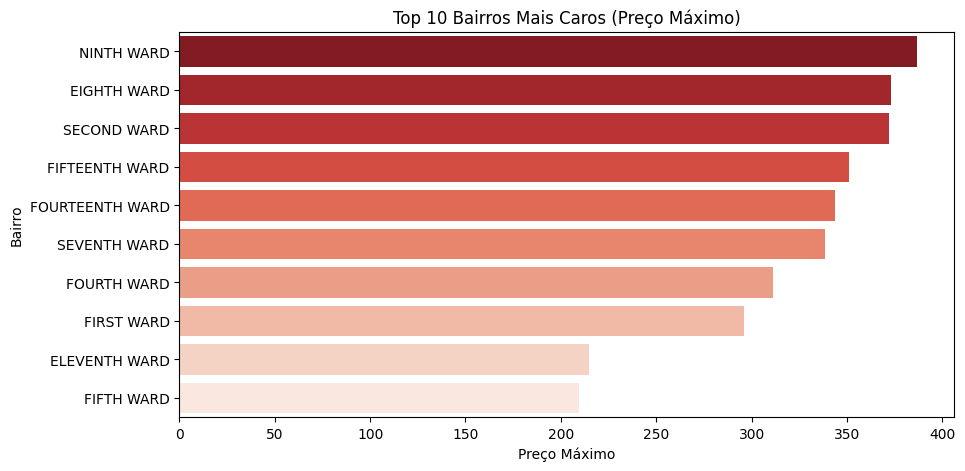

In [471]:
# Gráfico dos 10 bairros mais caros
plt.figure(figsize=(10, 5))
sns.barplot(x=caros.values, y=caros.index, palette='Reds_r')
plt.title('Top 10 Bairros Mais Caros (Preço Máximo)')
plt.xlabel('Preço Máximo')
plt.ylabel('Bairro')
plt.show()

/tmp/ipykernel_4548/1701651890.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=barato.values,y=barato.index,palette='Greens_r')


Text(0, 0.5, 'Bairro')

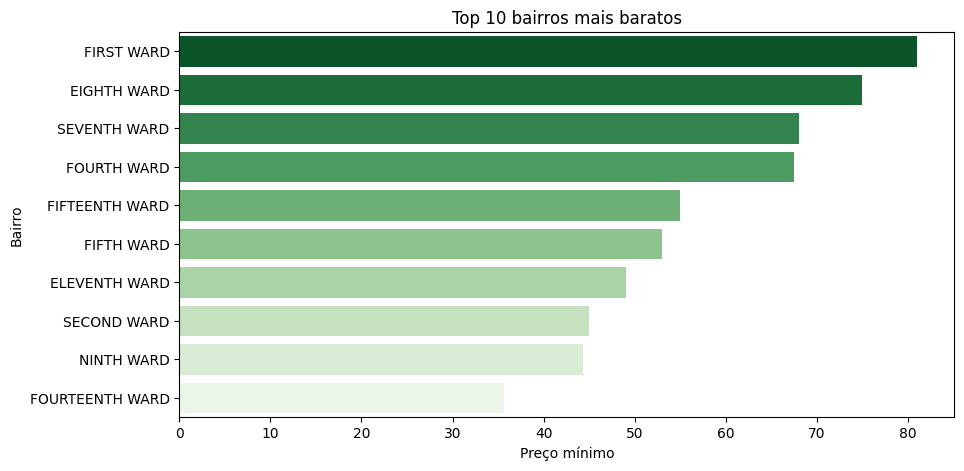

In [477]:
# Gráfico dos mais baratos

plt.figure(figsize=(10,5))
sns.barplot(x=barato.values,y=barato.index,palette='Greens_r')
plt.title("Top 10 bairros mais baratos")
plt.xlabel('Preço mínimo')
plt.ylabel('Bairro')

# Ao analisar ambos os gráficos  vemos

### P2. Preço por tipo de acomodação nos bairros com mais anúncios

In [448]:
df.groupby(['bairro','tipo_propriedade'])[['preco','total_anuncios_anfitriao']].max().head(10).sort_values(by='preco',ascending=False)

# As rental units são as unidades que possuem a maior quantidade de anúncios; o nosso Airbnb está buscando inquilinos que morem sozinhos

preco  total_anuncios_anfitriao
bairro         tipo_propriedade                                             
EIGHTH WARD    Entire home                  373.00                        20
FIFTEENTH WARD Entire cottage               351.00                         8
               Entire home                  350.00                         8
               Entire place                 262.00                         8
ELEVENTH WARD  Entire rental unit           214.67                        44
FIFTEENTH WARD Entire rental unit           207.00                         2
EIGHTH WARD    Entire rental unit           146.54                         6
               Private room in home          75.00                         2
ELEVENTH WARD  Private room in home          74.40                        13
               Private room in rental unit   71.00                         3

### P3. Superhosts cobram mais e têm avaliações melhores?

In [449]:
# Comparação de preço médio e nota geral média entre Superhosts e não-Superhosts
df.groupby('anfitriao_superhost')[['preco', 'nota_geral']].mean().round(2)
# Os superhosts cobram mais e são mais bem avaliados, provavelmente por terem acesso a mais serviços

,preco,nota_geral
anfitriao_superhost,,
False,147.24,4.59
True,162.65,4.89


### P4. Comodidades mais comuns e o efeito da piscina no preço

In [450]:
df['comodidades'].mode() # As comodidades mais comuns são as necessidades mais básicas: os clientes preferem simplicidade e o mesmo tipo de benefício

,comodidades
0,"[TV, Hangers, Smoke alarm, Hot water, Shampoo,..."


In [451]:
# Os nomes vêm com variações ("Pool", "Shared outdoor pool"...), então buscamos 'pool' no texto,
# ignorando falsos positivos: "Pool table" (sinuca), "Pool view" (só vista) e "Whirlpool" (marca de eletrodoméstico).
piscina = df_explodido['comodidades'].str.contains('pool', case=False, na=False) & \
          ~df_explodido['comodidades'].str.contains('table|view|whirlpool', case=False, na=False)

# O df_explodido serve para ACHAR quem tem piscina; a marcação vai no df (1 linha por anúncio)
df['tem_piscina'] = df['id'].isin(df_explodido.loc[piscina, 'id'])

df['tem_piscina'].value_counts()

,count
tem_piscina,
False,427
True,5


In [452]:
df.groupby('tem_piscina')['preco'].mean() # Quando há piscina, o preço das hospedagens aumenta em média 15%


,preco
tem_piscina,
False,154.542381
True,178.000000


### P5. Quantos anfitriões entraram no Airbnb a cada ano?

In [455]:
df['ano']=df['anfitriao_desde'].dt.strftime('%Y') # Criamos a coluna ano para identificar a quantidade de anfitriões por ano

In [466]:
df.groupby('id')['ano'].sum().value_counts().sort_index(ascending=False) # Este código mostra quantos anfitriões entraram por ano, e é notável que, ao longo dos anos, a quantidade de anfitriões vem crescendo, um sinal positivo pra empresa

,count
ano,
2026,87
2025,84
2024,64
2023,75
2022,32
2021,32
2020,13
2019,12
2018,14


### P6. Diária média em dólar
Cotação do dólar pela API do Banco Central (série 1, dólar comercial).

In [453]:
URL_DOLAR = 'https://api.bcb.gov.br/dados/serie/bcdata.sgs.1/dados/ultimos/1?formato=json'

In [482]:
# Requisição para a API do Banco Central para obter a cotação atual do dólar
response = requests.get(URL_DOLAR)
dados_dolar = response.json()

# Extraindo o valor da taxa de venda do dólar comercial
cotacao_dolar = float(dados_dolar[0]['valor'])

# Calculando a média em dólar
media = df['preco'].mean()
diaria_dol = media / cotacao_dolar

print(f"Cotação do Dólar obtida: R$ {cotacao_dolar:.2f}")
print(f"Diária média em Dólar: $ {diaria_dol:.2f}")

Cotação do Dólar obtida: R$ 5.33
Diária média em Dólar: $ 29.02


### Ao observarmos a média da diária em dólar, é visível a crise pela qual nossa moeda está passando. Vale a pena nossa empresa buscar investir parte do lucro em dólar devido à crise econômica pela qual o nosso país passa.

## 7. Exportação

Salva a base tratada em CSV e em um banco SQLite.

In [483]:
# Exportando os dados tratados para formato CSV
df.to_csv('dados_air_tratados.csv', index=False)

AttributeError: module 'pandas' has no attribute 'to_csv'

In [453]:
df.to_sql('dados_air_tratados.sql',index=False)

## 8. Conclusões

| Pergunta | Resposta |
| --- | --- |
| P1 | |
| P2 | As rental units são as unidades com a maior quantidade de anúncios; o nosso Airbnb está buscando inquilinos que morem sozinhos. |
| P3 | Os superhosts cobram mais e são mais bem avaliados, provavelmente por terem acesso a mais serviços. |
| P4 | As comodidades mais comuns são as necessidades mais básicas: os clientes preferem simplicidade e o mesmo tipo de benefício. Quando há piscina, o preço das hospedagens aumenta em média 15%. |
| P5 | Ao longo dos anos, a quantidade de anfitriões vem crescendo, um sinal positivo pra empresa. |
| P6 | A média da diária em dólar deixa visível a crise pela qual nossa moeda está passando. Vale a pena nossa empresa buscar investir parte do lucro em dólar devido à crise econômica do país. |

**Limitações:** *(ex.: preço do anúncio não é o preço pago; dados de uma única extração...)*

**Próximos passos:** *(ex.: modelo de previsão de preço, comparar com outras cidades...)*

# As principais conclusões inferidas